# Туризм в регионах России: исследование и проверка гипотез

**Заказчик:** агрегатор отелей.
**Цель:** понять, как менялась туристическая индустрия в 2018–2023 годах — где продают больше всего туристических услуг,
какие турпакеты популярны и как изменились предпочтения туристов. Результаты помогут сервису строить персонализированные
маршруты и маркетинговые стратегии.

**План работы**
1. Загрузка данных.
2. Предобработка: названия столбцов, типы, пропуски, некорректные значения.
3. Исследовательский анализ: распределение средств размещения, топ-10 регионов, динамика турпакетов.
4. Проверка гипотез.
5. Общие выводы и рекомендации.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats as st

# Функции предобработки лежат в src/tourism.py
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
import tourism as tr

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
ALPHA = 0.05  # уровень значимости для всех тестов
warnings.filterwarnings("ignore", category=FutureWarning)  # технические предупреждения библиотек
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Единый стиль графиков: светлый фон, приглушённая сетка, без лишних рамок
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "font.size": 11,
    "legend.frameon": False, "axes.axisbelow": True,
})


def thousands(ax, axis="y"):
    # Подписи осей с разделителем разрядов: 40 000 вместо 40000
    fmt = plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

## Шаг 1. Загрузка данных

| Файл | Содержание |
|---|---|
| `hotel.csv` | число гостиниц, хостелов, санаторно-курортных организаций и мест в них, 2018–2023 |
| `count_person_hotel.csv` | число людей, размещённых в гостиницах, 2023 |
| `tour_firm.csv` | число реализованных турпакетов, 2018–2023 |
| `tour_cost_2023.csv` | стоимость реализованных турпакетов, 2023, млн руб. |

Файлы читаются как строки (`dtype=str`), чтобы при загрузке не потерять служебные обозначения Росстата.

In [2]:
raw = tr.load_raw(ROOT / "data" / "raw")
HAS_HOTEL = "hotel" in raw  # без hotel.csv пропускаем только раздел 3.1

for name, df in raw.items():
    print(f"{name}: {df.shape[0]} строк, {df.shape[1]} столбцов")

hotel: 81 строк, 37 столбцов
person_hotel: 82 строк, 4 столбцов
tour_firm: 82 строк, 25 столбцов
tour_cost: 87 строк, 4 столбцов


In [3]:
raw["tour_firm"].head()

,Субъект,"Общее число турпакетов, реализованных населению, 2018","Общее число турпакетов, реализованных гражданам России по территории России, 2018","Общее число турпакетов, реализованных гражданам России по другим странам, 2018","Общее число турпакетов, реализованных гражданам других стран по территории России, 2018","Общее число турпакетов, реализованных населению, 2019","Общее число турпакетов, реализованных гражданам России по территории России, 2019","Общее число турпакетов, реализованных гражданам России по другим странам, 2019","Общее число турпакетов, реализованных гражданам других стран по территории России, 2019","Общее число турпакетов, реализованных населению, 2020","Общее число турпакетов, реализованных гражданам России по территории России, 2020","Общее число турпакетов, реализованных гражданам России по другим странам, 2020","Общее число турпакетов, реализованных гражданам других стран по территории России, 2020","Общее число турпакетов, реализованных населению, 2021","Общее число турпакетов, реализованных гражданам России по территории России, 2021","Общее число турпакетов, реализованных гражданам России по другим странам, 2021","Общее число турпакетов, реализованных гражданам других стран по территории России, 2021","Общее число турпакетов, реализованных населению, 2022","Общее число турпакетов, реализованных гражданам России по территории России, 2022","Общее число турпакетов, реализованных гражданам России по другим странам, 2022","Общее число турпакетов, реализованных гражданам других стран по территории России, 2022","Общее число турпакетов, реализованных населению, 2023","Общее число турпакетов, реализованных гражданам России по территории России, 2023","Общее число турпакетов, реализованных гражданам России по другим странам, 2023","Общее число турпакетов, реализованных гражданам других стран по территории России, 2023"
0,Белгородская область,14138,4333,9805,NaN,20646,4772,15874,NaN,9694,5462,4232,NaN,14901,5662,9239.0,NaN,15222,8887,6165,170.0,17733,11803,5930.0,NaN
1,Брянская область,9444,4438,5004,2.0,10459,4966,5492,1,3435,2336,1099,NaN,7301,3822,3479.0,NaN,11591,8265,3326,NaN,10165,5377,4788.0,NaN
2,Владимирская область,23900,12294,11243,363.0,23065,11558,10394,1113,7334,4282,2978,74.0,14730,8297,6426.0,7,18288,11359,6924,5.0,22334,13588,8737.0,9.0
3,Воронежская область,14554,8124,6430,NaN,14464,4613,9851,NaN,6681,3500,3181,NaN,16296,8373,7923.0,NaN,20958,13608,7350,NaN,24993,14781,10212.0,NaN
4,Ивановская область,17049,6592,10457,NaN,17019,8327,8692,NaN,6477,4167,2310,NaN,10167,5722,4445.0,NaN,13637,8575,5062,NaN,18904,11002,7902.0,NaN


## Шаг 2. Предобработка данных

### 2.1. Названия столбцов

Исходные названия длинные, на кириллице, с запятыми и двойными пробелами
(например, `Стоимость турпакетов  реализованных гражданам России…`). С такими именами неудобно работать в коде.

Вместо ручного перечисления десятков имён столбцы переименовываются по шаблону
`<показатель>, <год>` → `<короткое_имя>_<год>`. Если в данных появится незнакомый столбец, функция сообщит об ошибке,
а не переименует его молча.

| Было | Стало |
|---|---|
| Число гостиниц, 2018 | `hotels_2018` |
| Число мест в хостелах, 2023 | `beds_hostels_2023` |
| Общее число турпакетов, реализованных гражданам России по территории России, 2022 | `domestic_2022` |
| Общее число турпакетов, реализованных гражданам России по другим странам, 2022 | `outbound_2022` |
| Общее число турпакетов, реализованных гражданам других стран по территории России, 2022 | `inbound_2022` |
| Стоимость реализованных турпакетов в 2023 году, млн руб. | `cost_total_2023` |

In [4]:
renamed = tr.rename_columns(raw)

for name, df in renamed.items():
    print(f"{name:13}", list(df.columns[:6]), "...")

hotel         ['region', 'hotels_2018', 'hotels_2019', 'hotels_2020', 'hotels_2021', 'hotels_2022'] ...
person_hotel  ['region', 'guests_total_2023', 'guests_russian_2023', 'guests_foreign_2023'] ...
tour_firm     ['region', 'total_2018', 'domestic_2018', 'outbound_2018', 'inbound_2018', 'total_2019'] ...
tour_cost     ['region', 'cost_total_2023', 'cost_domestic_2023', 'cost_outbound_2023'] ...


### 2.2. Нечисловые значения

Посмотрим, какие значения в числовых столбцах не читаются как числа.

In [5]:
for name, df in renamed.items():
    bad = tr.find_non_numeric(df)
    print(f"\n{name}:")
    print(bad.to_string() if not bad.empty else "  всё читается как числа")


hotel:
…1    140

person_hotel:
  всё читается как числа

tour_firm:
…1    58

tour_cost:
…1    6


Основная причина строкового типа — обозначение **`…1`**. Это сноска Росстата: данные не публикуются,
чтобы обеспечить конфиденциальность первичных статистических данных (например, если в регионе одна-две организации
и по сводной цифре можно восстановить показатели конкретной компании).

Значит, `…1` — это **«неизвестно»**, а не ноль. Если заменить такие значения на 0 (как часто делают), средние
окажутся заниженными, а в тестах появятся искусственные значения. Поэтому `…1` и пустые ячейки переводятся в `NaN`.

### 2.3. Типы данных

Все показатели — количества и суммы, поэтому приводим их к `float`
(`float`, а не `int`, потому что в столбцах остаются `NaN`). Столбец `region` остаётся строкой.

In [6]:
numeric = {name: tr.to_numeric(df) for name, df in renamed.items()}

pd.DataFrame({
    name: df.dtypes.astype(str).value_counts()
    for name, df in numeric.items()
}).fillna(0).astype(int)

,hotel,person_hotel,tour_firm,tour_cost
float64,12,0,24,3
int64,24,3,0,0
str,1,1,1,1


### 2.4. Итоговые и вложенные строки

В статистических таблицах Росстата вместе с субъектами часто идут итоги: «Российская Федерация» и федеральные округа.
Кроме того, в `tour_cost_2023.csv` есть «матрёшка»: «Архангельская область» уже включает Ненецкий АО,
а рядом отдельно идут сам НАО и «Архангельская область (кроме НАО)». Так же устроена Тюменская область с ХМАО и ЯНАО.

Если оставить такие строки, одни и те же деньги посчитаются дважды, а итоги займут верх рейтинга.
В остальных таблицах области даны целиком, поэтому для единообразия оставляем строку «область целиком»
и убираем вложенные.

In [7]:
clean = {}
for name, df in numeric.items():
    regions, aggregates = tr.split_aggregates(df)
    clean[name] = regions
    dropped = aggregates["region"].tolist()
    print(f"{name}: убрано строк — {len(dropped)}", dropped)

hotel: убрано строк — 0 []
person_hotel: убрано строк — 0 []
tour_firm: убрано строк — 0 []
tour_cost: убрано строк — 5 ['Ненецкий автономный округ', 'Архангельская область (кроме Ненецкого автономного округа)', 'Ханты-Мансийский автономный округ - Югра', 'Ямало-Ненецкий автономный округ', 'Тюменская область без автономных округов']


### 2.5. Дубликаты

In [8]:
for name, df in clean.items():
    print(f"{name}: полных дубликатов — {df.duplicated().sum()}, повторов региона — {df['region'].duplicated().sum()}")
    clean[name] = df.drop_duplicates(subset="region").reset_index(drop=True)

df_hotel = clean.get("hotel")
df_person = clean["person_hotel"]
df_tour = clean["tour_firm"]
df_cost = clean["tour_cost"]

hotel: полных дубликатов — 0, повторов региона — 0
person_hotel: полных дубликатов — 0, повторов региона — 0
tour_firm: полных дубликатов — 0, повторов региона — 0
tour_cost: полных дубликатов — 0, повторов региона — 0


### 2.6. Пропуски

In [9]:
for name, df in clean.items():
    report = tr.missing_report(df)
    report = report[report["missing"] > 0]
    print(f"\n=== {name}: столбцов с пропусками — {len(report)} из {df.shape[1]} ===")
    if not report.empty:
        print(report.head(10).to_string())


=== hotel: столбцов с пропусками — 12 из 37 ===
                     dtype  missing  missing_share  unique
beds_hostels_2020  float64       19           0.23      61
beds_hostels_2019  float64       13           0.16      65
beds_hostels_2018  float64       13           0.16      63
beds_hostels_2021  float64       12           0.15      66
beds_spa_2022      float64       12           0.15      69
beds_spa_2021      float64       12           0.15      68
beds_spa_2019      float64       11           0.14      70
beds_spa_2018      float64       11           0.14      70
beds_spa_2020      float64       10           0.12      70
beds_spa_2023      float64       10           0.12      71

=== person_hotel: столбцов с пропусками — 0 из 4 ===

=== tour_firm: столбцов с пропусками — 24 из 25 ===
                 dtype  missing  missing_share  unique
inbound_2022   float64       40           0.49      27
inbound_2021   float64       39           0.48      30
inbound_2023   float64       3

**Возможные причины пропусков**

- **Конфиденциальность (`…1`).** В регионах с одной-двумя туркомпаниями или гостиницами данные не публикуются.
  Чаще всего это малые регионы: Ингушетия, Чукотка, Еврейская АО, Карачаево-Черкесия.
- **Отсутствие явления.** Почти половина пропусков приходится на турпакеты для иностранцев (`inbound_*`).
  Рядом стоят значения 1, 2, 5, поэтому пустая ячейка здесь, скорее всего, означает «продаж не было», а не «неизвестно».
  Из-за этого среднее по `inbound` считается только по регионам с продажами и завышено.
- **Ошибки выгрузки.** Значения могли потеряться при сведении таблиц.

**Как работаем с пропусками**

- Не заполняем нулями: это смещает средние вниз и добавляет в тесты значения, которых не было.
- Средние и рейтинги считаем по доступным значениям (`skipna`).
- В парном сравнении 2022 и 2023 годов берём только регионы, по которым есть данные за оба года.

**Как избежать в будущем**

- Разделять в выгрузке «0» (явления нет) и «нет данных» (`NaN` или отдельный код).
- Вести словарь данных с расшифровкой всех служебных обозначений.
- Проверять схему и типы при загрузке, чтобы нечисловые значения не превращали столбцы в строки.

### 2.7. Корректность значений

Проверим, что в данных нет отрицательных чисел и что значения согласуются между собой.

In [10]:
def negatives(df):
    num = df.drop(columns="region")
    return int((num < 0).sum().sum())

for name, df in clean.items():
    print(f"{name}: отрицательных значений — {negatives(df)}")

checks = {}

# Мест не может быть меньше, чем организаций (если организации есть)
if HAS_HOTEL:
    for year in range(2018, 2024):
        for org, beds in [("hotels", "beds_hotels"), ("hostels", "beds_hostels"), ("spa_orgs", "beds_spa")]:
            o, b = df_hotel[f"{org}_{year}"], df_hotel[f"{beds}_{year}"]
            checks[f"{beds} < {org}, {year}"] = int(((b < o) & (o > 0)).sum())

# Россияне + иностранцы не должны заметно превышать общее число размещённых
diff = df_person["guests_russian_2023"] + df_person["guests_foreign_2023"] - df_person["guests_total_2023"]
checks["гости: россияне + иностранцы > всего"] = int((diff > 1).sum())

# Части стоимости турпакетов не должны превышать общую стоимость
parts = df_cost["cost_domestic_2023"] + df_cost["cost_outbound_2023"]
checks["стоимость: части > всего"] = int((parts > df_cost["cost_total_2023"] * 1.001).sum())

pd.Series(checks, name="нарушений").loc[lambda s: s > 0].to_frame() if any(checks.values()) else "Логических нарушений не найдено"

hotel: отрицательных значений — 0
person_hotel: отрицательных значений — 0
tour_firm: отрицательных значений — 0
tour_cost: отрицательных значений — 0


'Логических нарушений не найдено'

**Вывод по предобработке.** Столбцы переименованы в короткие латинские имена. Служебные обозначения `…1`
и пустые ячейки переведены в `NaN`, все показатели приведены к `float`. Названия регионов приведены к одному виду
(`г.Москва` → `г. Москва`). Итоговые и вложенные строки убраны, чтобы не считать данные дважды.
Больше всего пропусков в турпакетах для иностранцев: почти в половине регионов таких продаж нет.

## Шаг 3. Исследовательский анализ

### 3.1. Распределение гостиниц, хостелов и санаторно-курортных организаций, 2018–2023

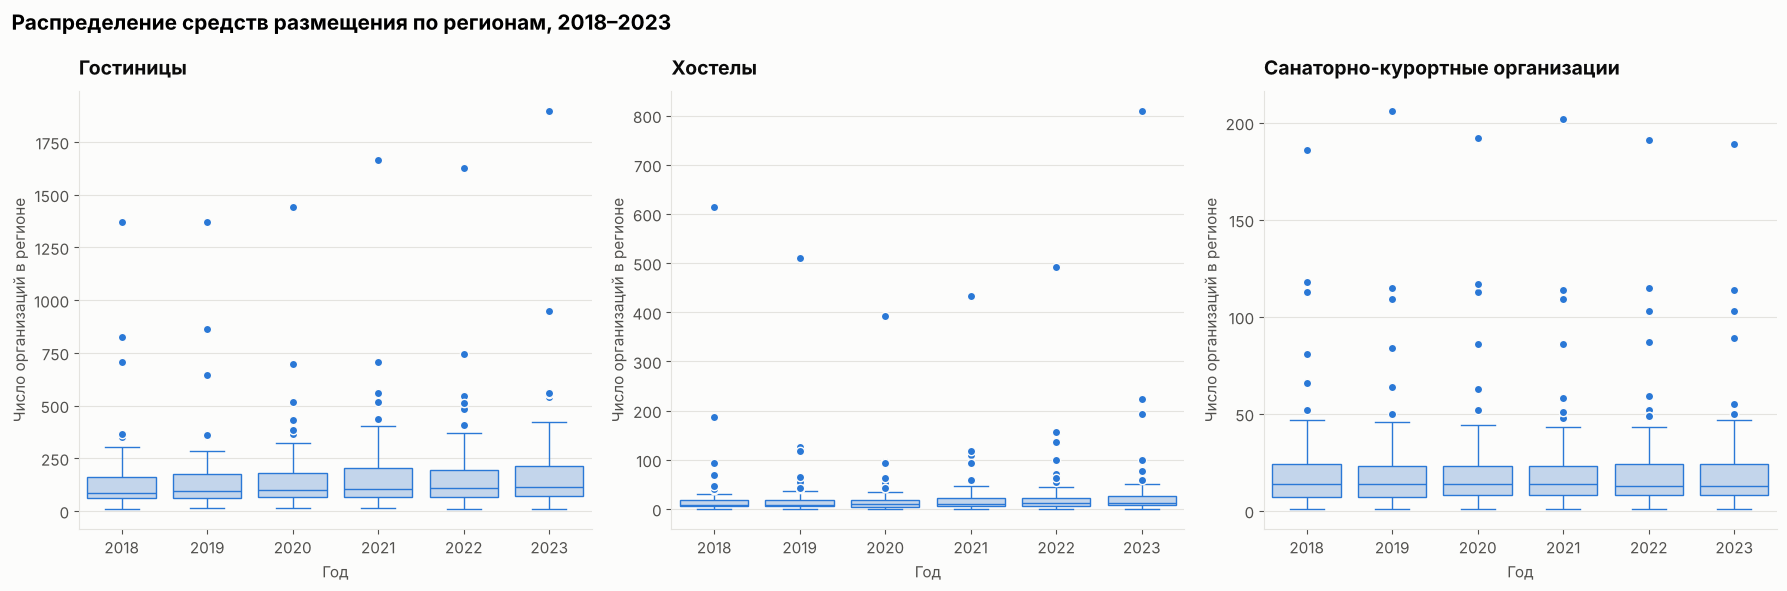

In [11]:
titles = {"hotels": "Гостиницы", "hostels": "Хостелы", "spa_orgs": "Санаторно-курортные организации"}

if HAS_HOTEL:
    long_hotel = tr.wide_to_long(df_hotel, list(titles))
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax, (col, title) in zip(axes, titles.items()):
        sns.boxplot(data=long_hotel, x="year", y=col, ax=ax, color="#bcd4f2", linecolor=BLUE,
                    flierprops={"markerfacecolor": BLUE, "markeredgecolor": "#fcfcfb", "markersize": 6})
        ax.set_title(title)
        ax.set_xlabel("Год")
        ax.set_ylabel("Число организаций в регионе")
    fig.suptitle("Распределение средств размещения по регионам, 2018–2023",
                 fontsize=15, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "01_accommodation_boxplots.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("hotel.csv не загружен — раздел 3.1 пропущен. Положите файл в data/raw и перезапустите ноутбук.")

In [12]:
# Медиана и межквартильный размах (IQR) по годам — те же «ящики» в цифрах
def iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)

if HAS_HOTEL:
    display_table = long_hotel.groupby("year")[list(titles)].agg(["median", iqr]).round(1)
else:
    display_table = "—"
display_table

hotels        hostels       spa_orgs      
     median    iqr  median   iqr   median   iqr
year                                           
2018  87.00  99.00    8.00 13.00    14.00 17.00
2019  96.00 112.00    8.00 13.00    14.00 16.00
2020 100.00 114.00    9.00 15.00    14.00 15.00
2021 103.00 139.00   10.00 17.00    14.00 15.00
2022 111.00 128.00   11.00 17.00    13.00 16.00
2023 113.00 140.00   12.00 19.00    13.00 16.00

**Наблюдения**

- **Гостиниц становится больше.** Медианный регион вырос с 87 гостиниц в 2018 году до 113 в 2023-м (+30%),
  всего по стране — с 11,7 до 14,4 тыс. Пандемия рост лишь притормозила. Лидер с большим отрывом — Краснодарский край
  (1 896 гостиниц, вдвое больше Москвы), это главные выбросы на графике.
- **Хостелы — самый быстрорастущий формат.** Медиана выросла с 8 до 12 на регион, общее число — с 1,8 до 2,6 тыс.,
  причём основной рост пришёлся на 2022–2023 годы. Рынок хостелов сосредоточен в столицах:
  Москва (809), Московская область (223) и Санкт-Петербург (193).
- **Санатории стоят на месте.** Медиана — 13–14 организаций на регион все шесть лет. Выбросы — курортные регионы:
  Краснодарский и Ставропольский края, Крым.

Распределения сильно скошены вправо, поэтому для «типичного региона» правильнее опираться на медиану, а не на среднее.

#### Проверка: сколько мест приходится на один хостел

Вместе с числом хостелов резко выросло число мест в них. Проверим, правдоподобны ли значения.

In [13]:
if HAS_HOTEL:
    beds_per_hostel = (
        df_hotel.assign(beds_per_hostel=df_hotel["beds_hostels_2023"] / df_hotel["hostels_2023"])
        [["region", "hostels_2023", "beds_hostels_2023", "beds_per_hostel"]]
        .dropna()
        .sort_values("beds_per_hostel", ascending=False)
    )
    print(f"Медиана по регионам: {beds_per_hostel['beds_per_hostel'].median():.0f} мест на хостел")
    msk = df_hotel["region"].isin(["г. Москва", "Московская область"])
    print(f"Доля Москвы и Московской области во всех местах в хостелах, 2023: "
          f"{df_hotel.loc[msk, 'beds_hostels_2023'].sum() / df_hotel['beds_hostels_2023'].sum():.0%}")
    display_table = beds_per_hostel.head(5).round(0)
else:
    display_table = "—"
display_table

Медиана по регионам: 45 мест на хостел
Доля Москвы и Московской области во всех местах в хостелах, 2023: 71%


,region,hostels_2023,beds_hostels_2023,beds_per_hostel
17,г. Москва,809,"224,578.00",278.00
38,Карачаево-Черкесская Республика,4,"1,005.00",251.00
9,Московская область,223,"55,395.00",248.00
27,г. Санкт-Петербург,193,"31,659.00",164.00
76,Амурская область,18,"2,401.00",133.00


**Аномалия в данных.** В типичном регионе на один хостел приходится около 45 мест, а в Москве — 278,
в Московской области — 248. Хостелы такого размера маловероятны: скорее всего, туда попали общежития
или рабочие хостелы, либо места учитываются иначе. На Москву и область приходится 71% всех мест в хостелах страны,
так что эта особенность определяет весь рост показателя. Число мест в хостелах стоит использовать
с осторожностью и уточнить методику у поставщика данных.

### 3.2. Топ-10 регионов по стоимости реализованных турпакетов в 2023 году

Лидер: г. Москва — 54.6% всей стоимости турпакетов
Доля топ-10: 74.5%


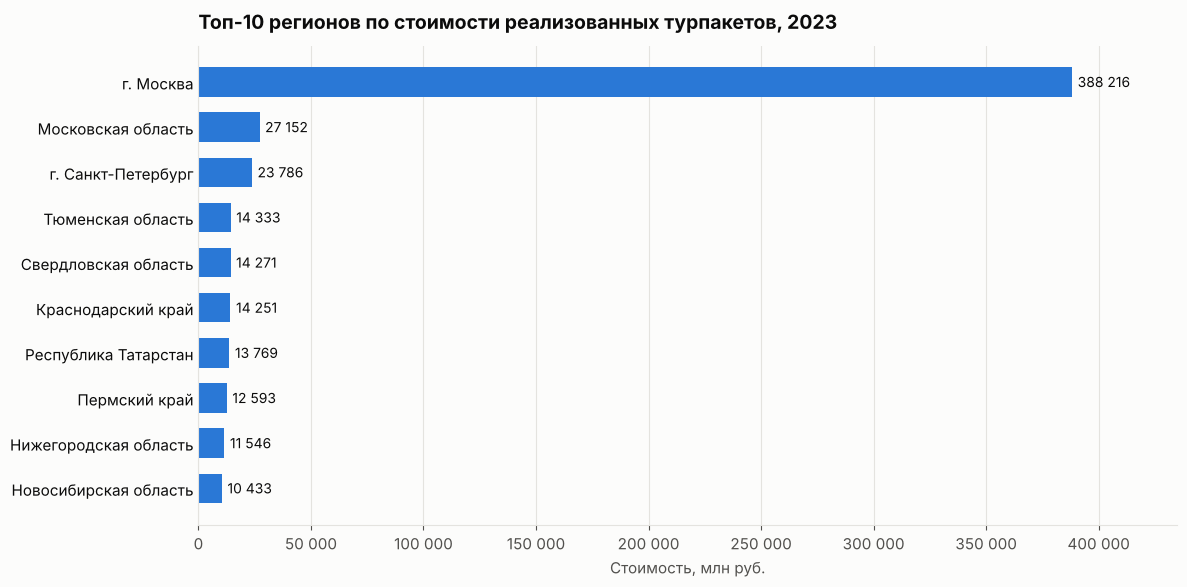

In [14]:
top10 = df_cost.dropna(subset=["cost_total_2023"]).nlargest(10, "cost_total_2023")

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(top10["region"], top10["cost_total_2023"], color=BLUE, height=0.65)
ax.invert_yaxis()
ax.bar_label(ax.containers[0], labels=[f"{v:,.0f}".replace(",", " ") for v in top10["cost_total_2023"]],
             padding=4, color=INK, fontsize=10)
ax.set_title("Топ-10 регионов по стоимости реализованных турпакетов, 2023")
ax.set_xlabel("Стоимость, млн руб.")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0, labelcolor=INK)
thousands(ax, "x")
ax.set_xlim(0, top10["cost_total_2023"].max() * 1.12)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_top10_regions_cost.png", dpi=150, bbox_inches="tight")
plt.show()

total = df_cost["cost_total_2023"].sum()
leader = top10.iloc[0]
print(f"Лидер: {leader['region']} — {leader['cost_total_2023'] / total:.1%} всей стоимости турпакетов")
print(f"Доля топ-10: {top10['cost_total_2023'].sum() / total:.1%}")

**Наблюдения**

- Рынок турпакетов сверхконцентрирован: на **Москву приходится более половины** всей стоимости
  реализованных турпакетов (около 388 млрд руб.). Второе место, Московская область, отстаёт в 14 раз.
- На топ-10 регионов приходится около трёх четвертей рынка. Кроме столиц, в него входят крупные промышленные регионы
  (Тюменская и Свердловская области, Татарстан, Пермский край, Нижегородская и Новосибирская области)
  и курортный Краснодарский край.
- Поэтому любые средние по регионам определяются в первую очередь Москвой.

In [15]:
# Куда тратят деньги: доля внутренних и зарубежных турпакетов в стоимости
cost_split = df_cost[["cost_domestic_2023", "cost_outbound_2023"]].sum()
print(f"По России: {cost_split['cost_domestic_2023'] / cost_split.sum():.1%}, "
      f"за рубеж: {cost_split['cost_outbound_2023'] / cost_split.sum():.1%}")

По России: 23.2%, за рубеж: 76.8%


Внутренних турпакетов продаётся больше, чем зарубежных (см. 3.3), но по деньгам картина обратная:
около трёх четвертей стоимости приходится на поездки за рубеж. Зарубежный турпакет в среднем намного дороже.

### 3.3. Динамика среднего числа турпакетов по категориям, 2018–2023

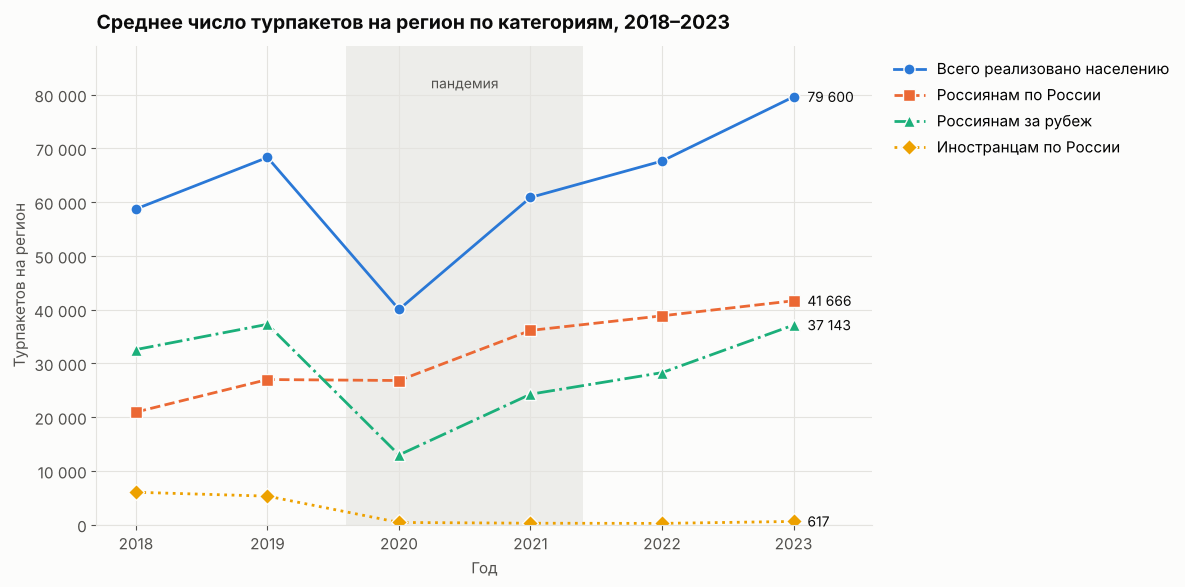

,total,domestic,outbound,inbound
year,,,,
2018,"58,742.00","20,957.00","32,586.00","6,047.00"
2019,"68,329.00","27,015.00","37,288.00","5,322.00"
2020,"40,049.00","26,834.00","12,980.00",428.00
2021,"60,888.00","36,151.00","24,283.00",286.00
2022,"67,656.00","38,866.00","28,295.00",252.00
2023,"79,600.00","41,666.00","37,143.00",617.00


In [16]:
long_tour = tr.wide_to_long(df_tour, ["total", "domestic", "outbound", "inbound"])
avg_tour = long_tour.groupby("year")[["total", "domestic", "outbound", "inbound"]].mean()

labels = {
    "total": "Всего реализовано населению",
    "domestic": "Россиянам по России",
    "outbound": "Россиянам за рубеж",
    "inbound": "Иностранцам по России",
}
# Цвет + маркер + тип линии: категории различимы и при нарушениях цветовосприятия, и при печати
styles = {
    "total": (BLUE, "o", "-"),
    "domestic": (ORANGE, "s", "--"),
    "outbound": (AQUA, "^", "-."),
    "inbound": (YELLOW, "D", ":"),
}

fig, ax = plt.subplots(figsize=(12, 6))
ax.axvspan(2019.6, 2021.4, color=GRID, alpha=0.6, lw=0)
ax.text(2020.5, avg_tour.values.max() * 1.02, "пандемия", ha="center", color=INK_MUTED, fontsize=10)
for col, label in labels.items():
    color, marker, ls = styles[col]
    plt.plot(avg_tour.index, avg_tour[col], color=color, marker=marker, linestyle=ls,
             linewidth=2, markersize=8, markeredgecolor="#fcfcfb", label=label)
    # Подпись в конце линии, чтобы не искать её в легенде
    ax.annotate(f"{avg_tour[col].iloc[-1]:,.0f}".replace(",", " "), (avg_tour.index[-1], avg_tour[col].iloc[-1]),
                xytext=(10, 0), textcoords="offset points", va="center", color=INK, fontsize=10)
ax.set_title("Среднее число турпакетов на регион по категориям, 2018–2023")
ax.set_xlabel("Год")
ax.set_ylabel("Турпакетов на регион")
ax.set_xlim(2017.7, 2023.6)
ax.set_ylim(0, avg_tour.values.max() * 1.12)
thousands(ax)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(FIG_DIR / "03_tour_packages_dynamics.png", dpi=150, bbox_inches="tight")
plt.show()

avg_tour.round(0)

In [17]:
# Изменение год к году, %
avg_tour.pct_change().mul(100).round(1)

,total,domestic,outbound,inbound
year,,,,
2018,NaN,NaN,NaN,NaN
2019,16.30,28.90,14.40,-12.00
2020,-41.40,-0.70,-65.20,-92.00
2021,52.00,34.70,87.10,-33.30
2022,11.10,7.50,16.50,-11.60
2023,17.70,7.20,31.30,144.50


**Наблюдения**

- **2020 год.** Общие продажи упали примерно на 40%, но почти целиком за счёт выездного туризма (−65%)
  и въездного (−92%). Внутренний туризм в пандемию почти не просел и стал «подушкой» для рынка.
- **Внутренний туризм** растёт весь период: среднее на регион за 2018–2023 годы увеличилось примерно вдвое.
  Темп роста замедляется: +35% в 2021-м, около +7% в 2022 и 2023 годах.
- **Выездной туризм** восстановился к 2023 году до уровня 2019-го, рост в 2023 году — около +30%.
- **Въездной туризм** так и не восстановился: в 2023 году он примерно в 10 раз меньше, чем в 2018-м.
- В 2023 году общее число турпакетов на регион — максимум за весь период.

### 3.4. Где размещается больше всего гостей (2023)

Доля иностранцев среди гостей: 4.6%


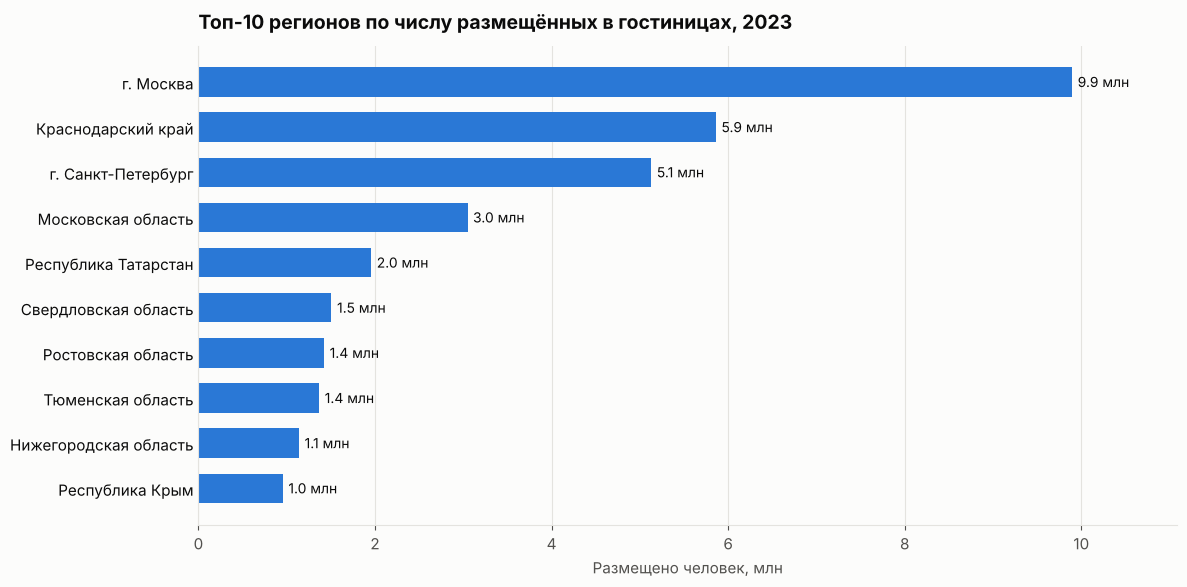

In [18]:
top_guests = df_person.nlargest(10, "guests_total_2023")

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(top_guests["region"], top_guests["guests_total_2023"] / 1e6, color=BLUE, height=0.65)
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt="%.1f млн", padding=4, color=INK, fontsize=10)
ax.set_title("Топ-10 регионов по числу размещённых в гостиницах, 2023")
ax.set_xlabel("Размещено человек, млн")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0, labelcolor=INK)
ax.set_xlim(0, top_guests["guests_total_2023"].max() / 1e6 * 1.12)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_top10_regions_guests.png", dpi=150, bbox_inches="tight")
plt.show()

guests = df_person[["guests_total_2023", "guests_foreign_2023"]].sum()
print(f"Доля иностранцев среди гостей: {guests['guests_foreign_2023'] / guests['guests_total_2023']:.1%}")

**Наблюдения.** По числу гостей лидируют Москва, Краснодарский край и Санкт-Петербург. Краснодарский край
занимает здесь второе место, хотя по стоимости турпакетов он только шестой: на курорты часто едут самостоятельно,
без турпакета. Иностранцев среди гостей меньше 5%, гостиничный рынок держится на внутреннем спросе.

## Шаг 4. Проверка гипотез

### 4.1. Средняя стоимость турпакетов в 2023 году больше 800 млн руб.?

Утверждение СМИ: средняя стоимость реализованных турпакетов на регион в 2023 году — 800 млн руб.
Аналитики считают, что она больше.

- **H₀:** средняя стоимость = 800 млн руб.
- **H₁:** средняя стоимость > 800 млн руб.

Используем одновыборочный t-тест с односторонней альтернативой. Регионы без данных исключаем:
если оставить `NaN`, тест вернёт `nan` вместо p-value.

In [19]:
cost_2023 = df_cost["cost_total_2023"].dropna()
MU_0 = 800

print(f"Регионов в выборке: {len(cost_2023)}")
print(f"Среднее: {cost_2023.mean():,.1f} млн руб., медиана: {cost_2023.median():,.1f} млн руб.")
print(f"Асимметрия: {cost_2023.skew():.2f}")

t_res = st.ttest_1samp(cost_2023, MU_0, alternative="greater")
print(f"\nt = {t_res.statistic:.3f}, p-value = {t_res.pvalue:.4f}")
print("Отвергаем H₀" if t_res.pvalue < ALPHA else "Не удалось отвергнуть H₀")

Регионов в выборке: 80
Среднее: 8,894.7 млн руб., медиана: 2,533.3 млн руб.
Асимметрия: 8.76

t = 1.674, p-value = 0.0490
Отвергаем H₀


Распределение стоимости сильно скошено (несколько регионов-лидеров), поэтому дополнительно проверим вывод
бутстрепом: построим одностороннюю 95%-ю нижнюю границу для среднего без предположения о нормальности.

In [20]:
rng = np.random.default_rng(42)
boot_means = np.array([rng.choice(cost_2023.values, size=len(cost_2023), replace=True).mean() for _ in range(10_000)])
lower_bound = np.quantile(boot_means, ALPHA)

print(f"Бутстреп: нижняя 95%-я граница среднего = {lower_bound:,.1f} млн руб.")
print("Граница выше 800 — подтверждает H₁" if lower_bound > MU_0 else "Граница не выше 800 — H₁ не подтверждается")

Бутстреп: нижняя 95%-я граница среднего = 3,487.2 млн руб.
Граница выше 800 — подтверждает H₁


Проверим также, не держится ли вывод на одной Москве: повторим тест без неё и применим критерий Уилкоксона,
который не чувствителен к выбросам.

In [21]:
no_moscow = df_cost.loc[df_cost["region"] != "г. Москва", "cost_total_2023"].dropna()
t_no_msk = st.ttest_1samp(no_moscow, MU_0, alternative="greater")
wil_1s = st.wilcoxon(cost_2023 - MU_0, alternative="greater")

pd.DataFrame({
    "проверка": ["t-тест, все регионы", "t-тест без Москвы", "Уилкоксон (медиана > 800)"],
    "p-value": [t_res.pvalue, t_no_msk.pvalue, wil_1s.pvalue],
}).assign(**{"вывод": lambda d: np.where(d["p-value"] < ALPHA, "отвергаем H₀", "не отвергаем H₀")})

,проверка,p-value,вывод
0,"t-тест, все регионы",0.05,отвергаем H₀
1,t-тест без Москвы,0.00,отвергаем H₀
2,Уилкоксон (медиана > 800),0.00,отвергаем H₀


**Интерпретация.** p-value — это вероятность получить такое или более экстремальное среднее при условии,
что верна H₀. На всех регионах t-тест даёт p ≈ 0.049, то есть на самой границе значимости. Причина не в том,
что среднее близко к 800, а в Москве: её значение в десятки раз больше остальных и раздувает дисперсию.

Все устойчивые проверки дают однозначный результат. Без Москвы p-value на порядки меньше 0.05,
нижняя граница бутстрепа в несколько раз выше 800, а критерий Уилкоксона показывает, что даже **медиана**
(около 2,5 млрд руб.) превышает 800 млн руб. Ниже 800 млн руб. продаёт лишь меньшинство регионов.

**Вывод:** H₀ отвергаем. Средняя стоимость реализованных турпакетов на регион в 2023 году больше 800 млн руб.,
и утверждение СМИ занижает рынок.

### 4.2. В 2023 году россияне стали чаще покупать турпакеты по России, чем в 2022?

- **H₀:** среднее число турпакетов по России в 2023 году = в 2022 году.
- **H₁:** в 2023 году среднее больше.

Сравниваются **одни и те же регионы** в два года, поэтому выборки зависимые. Правильный тест — **парный t-тест**
(`ttest_rel`), а не тест для независимых выборок: последний игнорирует связь «регион — регион»
и из-за огромного разброса между регионами почти не видит изменений.

Для устойчивости к выбросам дополнительно используем непараметрический критерий Уилкоксона.

In [22]:
pair = df_tour[["region", "domestic_2022", "domestic_2023"]].dropna()
print(f"Регионов с данными за оба года: {len(pair)}")

change = pair["domestic_2023"] - pair["domestic_2022"]
print(f"Среднее 2022: {pair['domestic_2022'].mean():,.0f}, среднее 2023: {pair['domestic_2023'].mean():,.0f}")
print(f"Суммарно: {pair['domestic_2022'].sum():,.0f} → {pair['domestic_2023'].sum():,.0f} "
      f"({pair['domestic_2023'].sum() / pair['domestic_2022'].sum() - 1:+.1%})")
print(f"Регионов с ростом: {(change > 0).sum()} из {len(pair)}")

rel = st.ttest_rel(pair["domestic_2023"], pair["domestic_2022"], alternative="greater")
wil = st.wilcoxon(pair["domestic_2023"], pair["domestic_2022"], alternative="greater")
ind = st.ttest_ind(pair["domestic_2023"], pair["domestic_2022"], alternative="greater")

pd.DataFrame({
    "тест": ["Парный t-тест", "Уилкоксон (парный)", "t-тест для независимых выборок (для сравнения)"],
    "p-value": [rel.pvalue, wil.pvalue, ind.pvalue],
}).assign(**{"вывод": lambda d: np.where(d["p-value"] < ALPHA, "отвергаем H₀", "не отвергаем H₀")}).round(4)

Регионов с данными за оба года: 78
Среднее 2022: 38,866, среднее 2023: 42,724
Суммарно: 3,031,574 → 3,332,494 (+9.9%)
Регионов с ростом: 46 из 78


,тест,p-value,вывод
0,Парный t-тест,0.10,не отвергаем H₀
1,Уилкоксон (парный),0.07,не отвергаем H₀
2,t-тест для независимых выборок (для сравнения),0.43,не отвергаем H₀


**Интерпретация.** Суммарно внутренних турпакетов в 2023 году продано примерно на 10% больше, чем в 2022-м,
и рост есть в большинстве регионов. Но ни один тест не опускается ниже порога 0.05: парные тесты дают p ≈ 0.07–0.10.
Рост неравномерный: в одних регионах продажи заметно выросли, в других (например, в Крыму и Севастополе) упали,
и на уровне регионов этого недостаточно для статистически значимого вывода.

Тест для независимых выборок даёт p ≈ 0.43. Он смешивает разницу между годами с огромной разницей между регионами
и поэтому «не видит» изменение. Это наглядно показывает, почему здесь нужен парный тест.

**Вывод:** на уровне значимости 5% H₀ отвергнуть не удаётся. Тенденция к росту внутреннего туризма есть,
но по этим данным её нельзя считать статистически доказанной. Для уверенного вывода нужны данные
за больший период или по более мелким единицам (месяцы, туроператоры).

## Шаг 5. Итоги проверки гипотез

In [23]:
def verdict(p):
    return "подтверждается" if p < ALPHA else "не подтверждается"

print(f"1. Средняя стоимость турпакетов на регион в 2023 году > 800 млн руб.: "
      f"{verdict(t_res.pvalue)} (p = {t_res.pvalue:.4f}; медиана {cost_2023.median():,.0f} млн руб.)")
print(f"2. Рост числа турпакетов по России в 2023 году относительно 2022: "
      f"{verdict(rel.pvalue)} (парный t-тест, p = {rel.pvalue:.4f}; "
      f"рост в {(change > 0).sum()} регионах из {len(pair)})")

1. Средняя стоимость турпакетов на регион в 2023 году > 800 млн руб.: подтверждается (p = 0.0490; медиана 2,533 млн руб.)
2. Рост числа турпакетов по России в 2023 году относительно 2022: не подтверждается (парный t-тест, p = 0.0968; рост в 46 регионах из 78)


## Общие выводы и рекомендации

**Качество данных**
- В выгрузках смешаны «ноль» и «нет данных»: `…1` означает скрытое значение, а пустая ячейка — иногда отсутствие
  продаж, иногда неизвестность. Заполнение всего подряд нулями искажает средние и тесты.
- В таблице стоимости есть вложенные строки (область, её автономные округа, область без округов).
  Без их удаления суммы считаются дважды.
- Число мест в хостелах Москвы и Московской области неправдоподобно велико (около 250–280 мест на хостел
  при типичных ~45). Вероятно, туда попали общежития. Показатель нужно уточнить, прежде чем на него опираться.
- Названия регионов различаются между файлами (`г.Москва` и `г. Москва`, `Кемеровская область` и
  `Кемеровская область - Кузбасс`), что мешает объединению таблиц.
- Рекомендация: договориться с поставщиком о едином коде для «нет данных», едином справочнике регионов
  (лучше с кодом ОКАТО) и выгрузке субъектов отдельно от итогов.

**Рынок**
- Средств размещения становится больше: число гостиниц в типичном регионе за 2018–2023 годы выросло на 30%,
  хостелов — в полтора раза. Санаторно-курортный фонд не меняется.
- Рынок турпакетов сверхконцентрирован: Москва даёт больше половины стоимости, топ-10 регионов — около трёх четвертей.
- Внутренний туризм оказался самым устойчивым сегментом: он не упал в пандемию и вырос примерно вдвое за 2018–2023 годы,
  но его рост замедляется, и прирост 2023 года статистически не подтверждён.
- Выездной туризм восстановился до уровня 2019 года, и по деньгам именно он даёт около трёх четвертей рынка.
  Въездной туризм почти исчез.
- Средняя стоимость турпакетов на регион значительно выше 800 млн руб., причём это верно и для типичного региона,
  а не только из-за Москвы.

**Рекомендации сервису**
- **Внутренние направления — для охвата.** Это самый массовый и устойчивый сегмент. Стоит расширять подборки отелей
  и маршрутов по России, прежде всего вокруг курортных регионов (Краснодарский край, Крым, Алтай, Карелия),
  куда часто едут без турпакета, то есть напрямую ищут жильё.
- **Зарубежные направления — для выручки.** Таких поездок меньше, но они дороже. Имеет смысл развивать для них
  премиальные предложения и допродажи.
- **Региональная персонализация.** Москва и Санкт-Петербург — отдельный сегмент с большим платёжеспособным спросом.
  В крупных промышленных регионах (Урал, Поволжье, Сибирь) рынок тоже большой, и конкуренция за него ниже, чем в столицах.
- **Не ориентироваться на средние.** Из-за Москвы средние показатели по стране сильно завышены.
  Для планирования по регионам нужны медианы и сегментация.